<a href="https://colab.research.google.com/github/syifaST/simuteh--2330511062-/blob/main/notebook/P6_morfologi_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys
REPO = "https://github.com/syifaST/simuteh--2330511062-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

perlu = ["citra", "bersih", "mask_daun", "mask_bercak"]
if (not all(os.path.exists(f"data/sintetis/{d}") for d in perlu)
        or not os.path.exists("data/sintetis/label.csv")):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")


print("Folder kerja:", os.getcwd())
print("Isi src:", os.listdir("../src"))
print("Param ada:", os.path.exists("../hasil/param_praproses.json"))

Folder kerja: /content/simuteh/notebook
Isi src: ['buat_dataset_sintetis.py', 'utils_tepi.py', '__pycache__', 'praproses.py', 'utils_cv.py']
Param ada: True


In [ ]:
import sys
import os

SRC = os.path.abspath("../src")

if SRC not in sys.path:
    sys.path.insert(0, SRC)

print("Path src:", SRC)
print("Src terdaftar:", SRC in sys.path)

Path src: /content/simuteh/src
Src terdaftar: True


## **1.1**

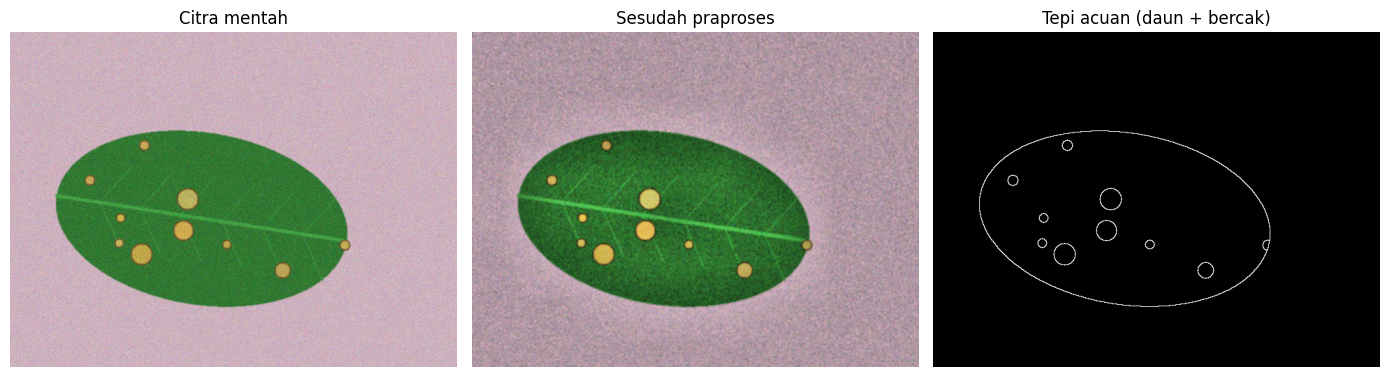

In [ ]:
import sys, json

sys.path.append("../src")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)

acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))

tampil(
    [img, pra, acuan],
    ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"]
)

## **1.3**

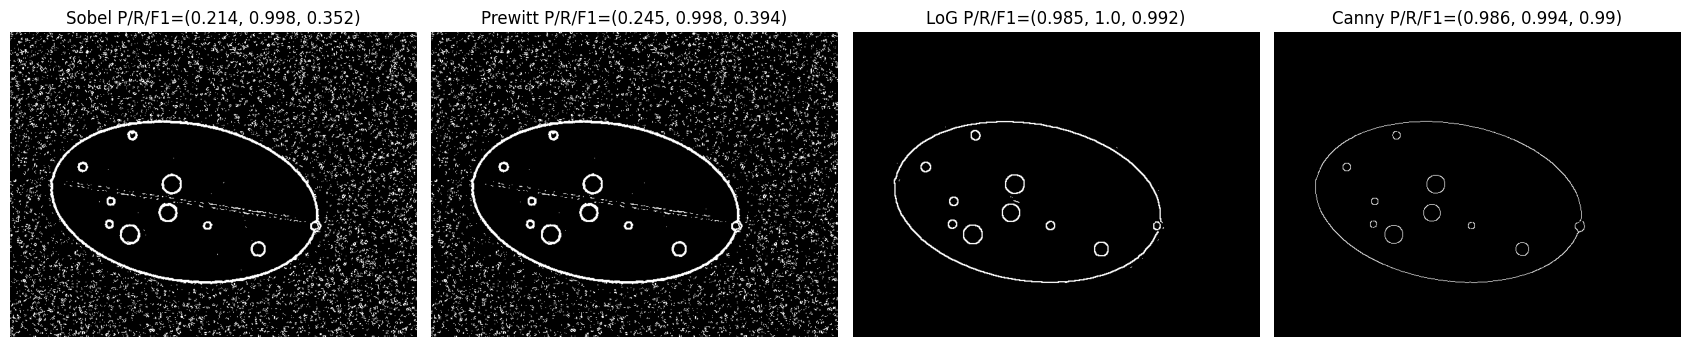

In [ ]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()),
       [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png"); plt.show()

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.995                   196              10           0.645
1  teh_021.png          0.996                   187               3           0.146
2  teh_011.png          0.997                   210               0               -


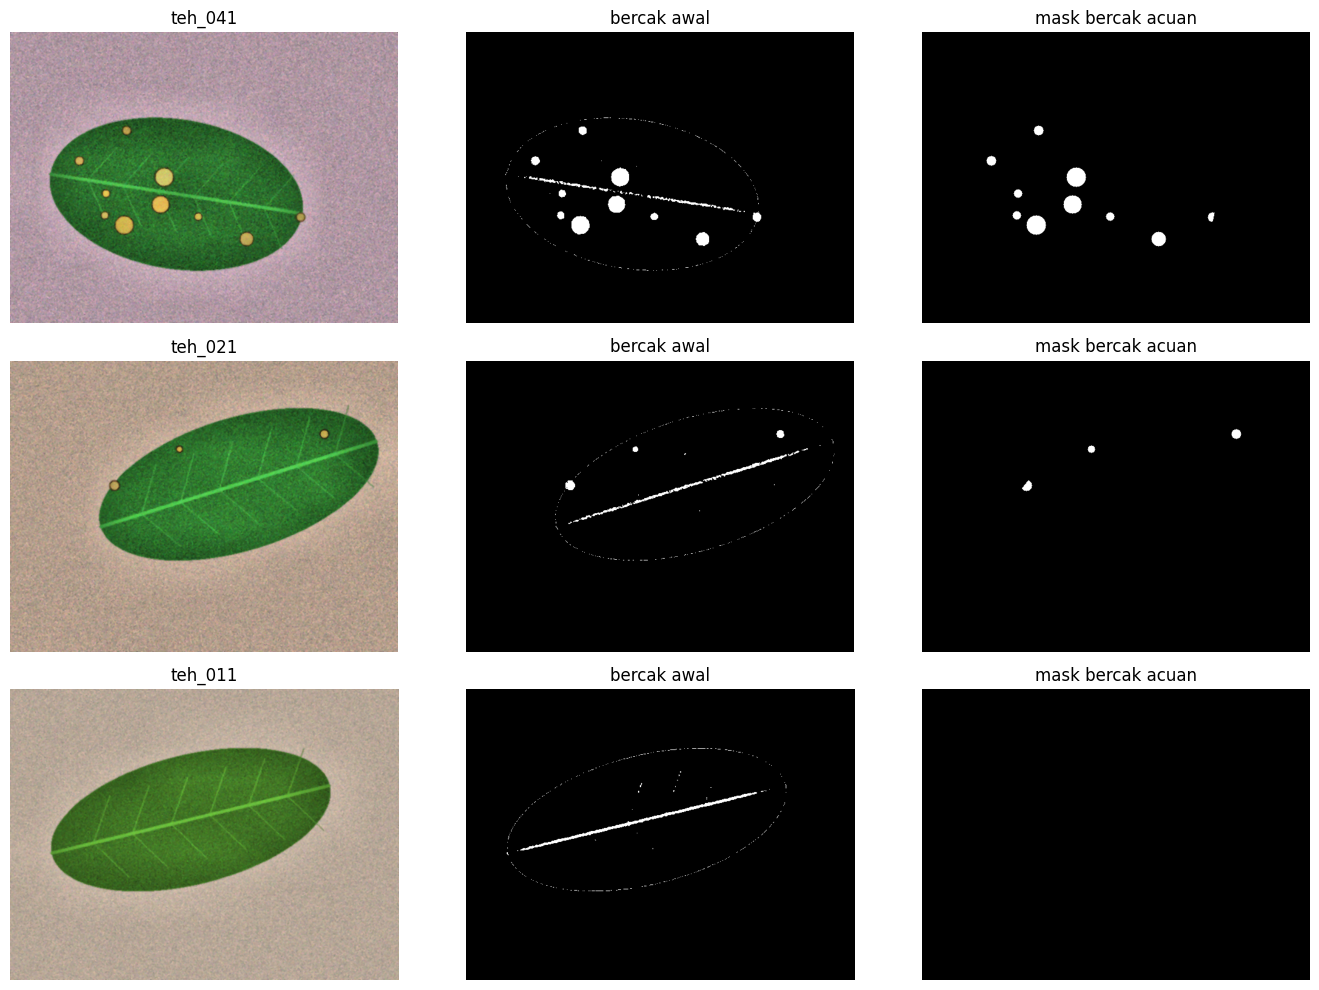

In [ ]:

def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8),
                                   connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0),
                  jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))


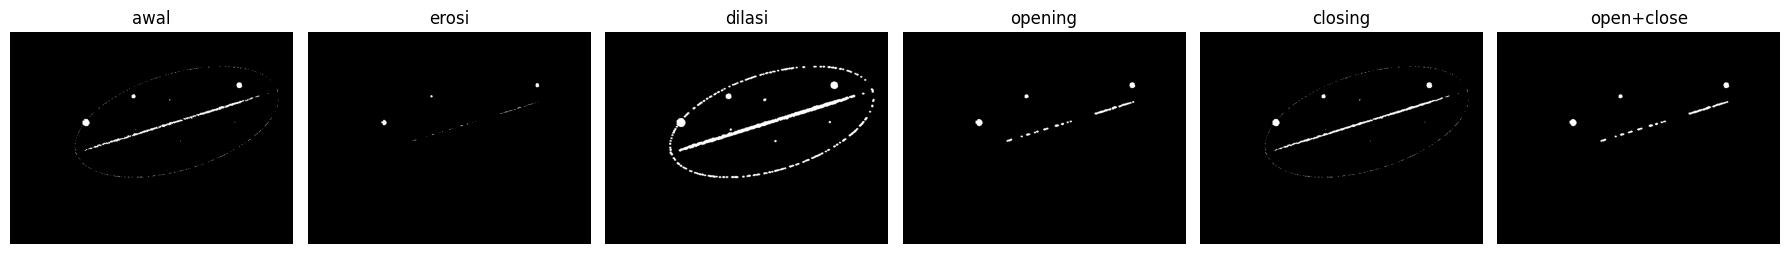

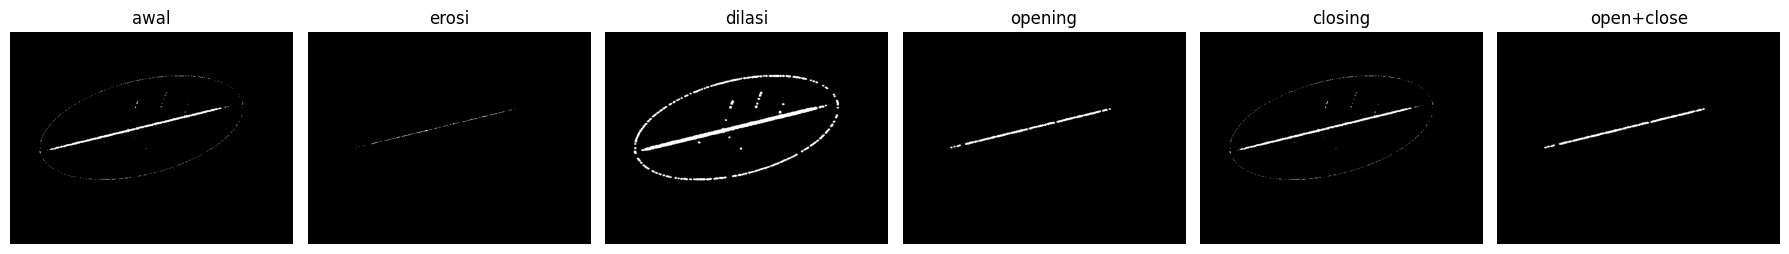

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       187    2198  0.146
1   teh_021.png       erosi        36     275  0.263
2   teh_021.png      dilasi        72    7170  0.069
3   teh_021.png     opening        16    1084  0.268
4   teh_021.png     closing       177    2333  0.139
5   teh_021.png  open+close        14    1108  0.263
6   teh_011.png        awal       210    2269      -
7   teh_011.png       erosi        49     268      -
8   teh_011.png      dilasi        64    7650      -
9   teh_011.png     opening         8    1583      -
10  teh_011.png     closing       209    2279      -
11  teh_011.png  open+close         4    1610      -


In [ ]:

SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
                                           cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.show()

print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))


In [ ]:

bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE,
          "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
                                     cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk,
                              abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])

eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran",
                                   "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)


                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.56   0.24        13.25  18.50  18.85
          5       0.59   0.36         3.10   3.55   2.80
          7       0.68   0.53         2.05   2.30   2.45
  persegi 3       0.56   0.28         6.50   7.25   7.00
          5       0.62   0.45         3.25   2.75   3.20
          7       0.67   0.56         0.70   0.35   0.00
  silang  3       0.56   0.24        13.25  18.50  18.85
          5       0.59   0.34         6.60   6.05   5.15
          7       0.69   0.49         4.45   3.95   4.60
4 elips   3       0.61   0.37         9.95  14.40  11.65
          5       0.64   0.48         3.30   2.60   2.50
          7       0.68   0.58         1.05   0.50   0.25
  persegi 3       0.62   0.41         6.00   5.65   4.95
          5       0.67   0.54         1.60   1.35   2.20
          7       0.65   0.52  

In [ ]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))  # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2],
                  skor_tepi(canny, ad)[2]])

print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))


                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.905     0.706
gelap                          0.981     0.693
kontras_rendah                 0.265     0.877
normal                         0.988     0.699
terang                         0.954     0.699


konektivitas 4: 14 komponen
konektivitas 8: 14 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      151     28.90         43.0       1.03         1.08  191  162
1       2      159     30.43         45.2       0.98         1.08  114  211
2       3      714    136.66         97.3       0.95         1.07  253  238
3       4       37      7.08         23.3       0.86         1.60  139  245
4       5       17      3.25         13.7       1.15         1.25  194  254
5       6      115     22.01         37.8       1.01         1.00  158  266
6       7      631    120.78         91.0       0.96         1.00  247  283
7       8       53     10.14         39.5       0.43         3.18  361  280
8       9       36      6.89         25.3       0.71         2.25  393  285
9      10      119     22.78         38.1       1.03         1.20  155  301
10     11      174     33.30         48.6       0.92         1.15  479  304
11     12      116     22.20    

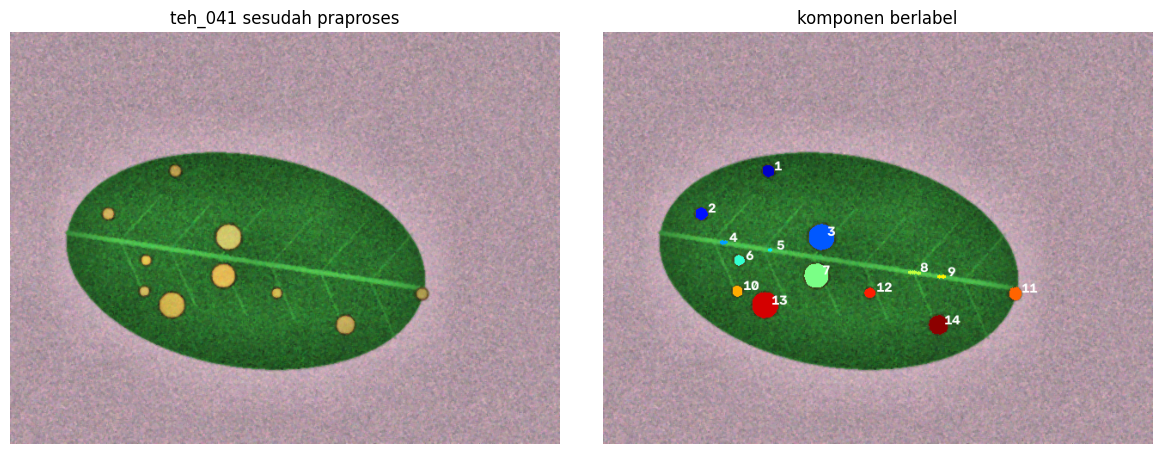

In [ ]:
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8),
                                                       connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8),
                                     cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
                      round(kebulatan, 2), round(rasio, 2),
                      int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan",
             "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun),
                                           cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8),
                          cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"],
       ukuran=(12, 4.5))


In [ ]:

def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) &
                    (tabel_k.kebulatan >= bulat_min) &
                    (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99),
          "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun),
                                               cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])

uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0)
      .groupby("aturan").palsu.sum())


kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.55    1.25    0.8
luas + kebulatan + rasio   1.10    0.60    0.3
luas >= 20                 2.50    2.00    1.5
tanpa saring               3.30    2.60    2.5
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             5
luas + kebulatan + rasio     4
luas >= 20                   9
tanpa saring                10
Name: palsu, dtype: int64
